# Experiment 4: Fuzzy Relation between Two Fuzzy Sets

**Aim:** To create and display a simple fuzzy relation between two fuzzy sets using Python.

## Theory
A **fuzzy relation** R from X to Y is a fuzzy subset of X × Y.
The relation built from fuzzy sets A (on X) and B (on Y) via the *Cartesian product* is:

μ_R(x, y) = min(μ_A(x), μ_B(y))

**Max-min composition** of R (X→Y) and S (Y→Z): μ_(R∘S)(x,z) = max_y min(μ_R(x,y), μ_S(y,z)).

### Step 1: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

### Step 2: Define two fuzzy sets

In [2]:
X = ['x1', 'x2', 'x3', 'x4']
Y = ['y1', 'y2', 'y3']
A = np.array([0.3, 0.7, 1.0, 0.5])
B = np.array([0.4, 0.9, 0.6])
print("A =", dict(zip(X, A)))
print("B =", dict(zip(Y, B)))

A = {'x1': np.float64(0.3), 'x2': np.float64(0.7), 'x3': np.float64(1.0), 'x4': np.float64(0.5)}
B = {'y1': np.float64(0.4), 'y2': np.float64(0.9), 'y3': np.float64(0.6)}


### Step 3: Create the fuzzy relation R = A × B (min operator)

In [3]:
R = np.minimum.outer(A, B)
R_df = pd.DataFrame(R, index=X, columns=Y)
print("Fuzzy Relation R (min):")
R_df

Fuzzy Relation R (min):


,y1,y2,y3
x1,0.3,0.3,0.3
x2,0.4,0.7,0.6
x3,0.4,0.9,0.6
x4,0.4,0.5,0.5


### Step 4: Alternative - product operator

In [4]:
R_prod = np.outer(A, B)
pd.DataFrame(R_prod, index=X, columns=Y).round(3)

,y1,y2,y3
x1,0.12,0.27,0.18
x2,0.28,0.63,0.42
x3,0.40,0.90,0.60
x4,0.20,0.45,0.30


### Step 5: Display relation as a heatmap

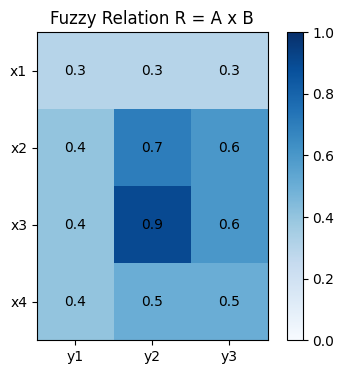

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(R, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(Y))); ax.set_xticklabels(Y)
ax.set_yticks(range(len(X))); ax.set_yticklabels(X)
for i in range(len(X)):
    for j in range(len(Y)):
        ax.text(j, i, f"{R[i,j]:.1f}", ha='center', va='center')
plt.colorbar(im); ax.set_title('Fuzzy Relation R = A x B'); plt.show()

### Step 6: Max-min composition with a second relation S (Y → Z)

In [6]:
Z = ['z1', 'z2']
C = np.array([0.8, 0.5])
S = np.minimum.outer(B, C)           # relation from Y to Z

def max_min_composition(R, S):
    out = np.zeros((R.shape[0], S.shape[1]))
    for i in range(R.shape[0]):
        for k in range(S.shape[1]):
            out[i, k] = np.max(np.minimum(R[i, :], S[:, k]))
    return out

T = max_min_composition(R, S)
print("S (Y->Z):"); print(pd.DataFrame(S, index=Y, columns=Z))
print("\nComposition T = R o S (X->Z):"); print(pd.DataFrame(T, index=X, columns=Z))

S (Y->Z):


     z1   z2
y1  0.4  0.4
y2  0.8  0.5
y3  0.6  0.5

Composition T = R o S (X->Z):
     z1   z2
x1  0.3  0.3
x2  0.7  0.5
x3  0.8  0.5
x4  0.5  0.5


### Step 7: Check properties

In [7]:
print("Height of R:", R.max())
print("Row-wise max:", R.max(axis=1))
print("Column-wise max:", R.max(axis=0))

Height of R: 0.9
Row-wise max: [0.3 0.7 0.9 0.5]
Column-wise max: [0.4 0.9 0.6]


## Conclusion
A fuzzy relation was constructed from two fuzzy sets using the min operator, displayed as a matrix and heatmap, and composed with another relation using max-min composition.